In [1]:
# preparing dataset
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

DATASET_DIR = "dataset_covid_vs_normal"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR  = os.path.join(DATASET_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

train_datagen = ImageDataGenerator(rescale=1./255,
                                   validation_split=0.2)

test_datagen  = ImageDataGenerator(rescale=1./255)

# normal= 0 ، covid= 1
train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],   # mapping 
    class_mode="binary",
    subset="training",
    shuffle=True
)

val_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],
    class_mode="binary",
    subset="validation",
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],
    class_mode="binary",
    shuffle=False
)


Found 33 images belonging to 2 classes.
Found 7 images belonging to 2 classes.
Found 10 images belonging to 2 classes.


In [3]:
# function of evaluation metrics
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

def eval_binery_model(model, test_generator, threshold=0.5,
                                 class_names=("normal", "covid"),
                               model_name="Model"):
                                 
  

    # real labels
    y_true = test_generator.classes

    # prediction of probability
    y_prob = model.predict(test_generator)
    y_pred = (y_prob >= threshold).astype(int).ravel()

    # dictionary for classification report 
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=list(class_names),
        output_dict=True,
        zero_division=0
    )

    # convert to dataframe
    report_df = pd.DataFrame(report_dict).T
    report_df = report_df.round(3)

    report_df = report_df.drop(
        index=["macro avg", "weighted avg"],
        errors="ignore"
    )
    print(f"\nEvaluation Results for {model_name}")
    print(report_df)

    # Confusion Matrix
    # labels=[1, 0]
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])

    # transpose: rows = Predicted , columns= True
    cm = cm.T

    cm_df = pd.DataFrame(
        cm,
        index=["Pred_covid", "Pred_normal"],
        columns=["True_covid", "True_normal"]
    )

    print("\nConfusion Matrix")
    print(cm_df)


    return report_df, cm_df


# implementation of LeNet-5

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_lenet5(input_shape=(224, 224, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # C1: Conv + ReLU + Pool
        layers.Conv2D(6, kernel_size=5, activation='relu', padding='same'),
        layers.AveragePooling2D(pool_size=2, strides=2),

        # C2: Conv + ReLU + Pool
        layers.Conv2D(16, kernel_size=5, activation='relu'),
        layers.AveragePooling2D(pool_size=2, strides=2),

        # Flatten + FC layers
        layers.Flatten(),
        layers.Dense(120, activation='relu'),
        layers.Dense(84, activation='relu'),

        # propability of class 1 (covid)
        layers.Dense(1, activation='sigmoid')
    ])
    return model

lenet5 = build_lenet5(input_shape=(224, 224, 3))
lenet5.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 112, 112, 6)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 108, 108, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 54, 54, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 46656)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     5,598,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,611,961 (21.41 MB)

 Trainable params: 5,611,961 (21.41 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# compile LeNet-5 model
lenet5.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [10]:
# train LeNet-5 model
EPOCHS = 15

history = lenet5.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen
)


Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 488ms/step - accuracy: 0.6061 - loss: 0.6514 - val_accuracy: 0.5714 - val_loss: 0.7571
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 457ms/step - accuracy: 0.5152 - loss: 0.5951 - val_accuracy: 0.7143 - val_loss: 0.6863
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 541ms/step - accuracy: 0.8182 - loss: 0.4132 - val_accuracy: 0.5714 - val_loss: 0.6362
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 515ms/step - accuracy: 0.9091 - loss: 0.3100 - val_accuracy: 0.8571 - val_loss: 0.5708
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 474ms/step - accuracy: 0.9697 - loss: 0.2342 - val_accuracy: 0.8571 - val_loss: 0.5783
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 457ms/step - accuracy: 0.9394 - loss: 0.1642 - val_accuracy: 0.5714 - val_loss: 0.7023
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 591ms/step - accuracy: 0.9394 - loss: 0.1447 - val_accuracy: 0.7143 - val_loss: 0.6475
Epoch 8/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 761ms/step - accuracy: 0.9697 - loss: 0.1141 - val_accuracy: 0.7143 - val_loss:

In [12]:
# metrics and results of LeNet-5 model

lenet_report, lenet_cm = eval_binery_model(lenet5, test_gen)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 428ms/step

Evaluation Results for Model
          precision  recall  f1-score  support
normal          1.0     1.0       1.0      4.0
covid           1.0     1.0       1.0      6.0
accuracy        1.0     1.0       1.0      1.0

Confusion Matrix
             True_covid  True_normal
Pred_covid            6            0
Pred_normal           0            4


# implementation of AlexNet

In [80]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_alexnet(input_shape=(224, 224, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Conv1
        layers.Conv2D(96, kernel_size=11, strides=4, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=3, strides=2),

        # Conv2
        layers.Conv2D(256, kernel_size=5, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=3, strides=2),

        # Conv3
        layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),

        # Conv4
        layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),

        # Conv5
        layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=3, strides=2),

        # Fully Connected
        layers.Flatten(),
        layers.Dense(4096, activation='relu'),
        layers.Dense(4096, activation='relu'),

        # propability of class1
        layers.Dense(1, activation='sigmoid')
    ])
    return model

alexnet = build_alexnet(input_shape=(224, 224, 3))
alexnet.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,285,441 (222.34 MB)

 Trainable params: 58,285,441 (222.34 MB)

 Non-trainable params: 0 (0.00 B)

In [82]:
# compile AlexNet model
alexnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [84]:
# train AlexNet model
EPOCHS = 15
history_alex = alexnet.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen
)

Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.4242 - loss: 0.7919 - val_accuracy: 0.4286 - val_loss: 0.6914
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.6061 - loss: 0.6854 - val_accuracy: 0.5714 - val_loss: 0.6673
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.5152 - loss: 0.6854 - val_accuracy: 0.5714 - val_loss: 0.6785
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.5152 - loss: 0.6759 - val_accuracy: 0.5714 - val_loss: 0.6583
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5455 - loss: 0.6240 - val_accuracy: 0.5714 - val_loss: 0.6078
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.8788 - loss: 0.4573 - val_accuracy: 0.7143 - val_loss: 0.6058
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9394 - loss: 0.1514 - val_accuracy: 0.7143 - val_loss: 1.3681
Epoch 8/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.9697 - loss: 0.2132 - val_accuracy: 0.5714 - val_loss: 1.4498
Epoch 9/1

In [86]:
# metrics and results of AlexNet
alex_report, alex_cm = eval_binery_model(alexnet, test_gen)

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 633ms/step

Evaluation Results for Model
          precision  recall  f1-score  support
normal          1.0     1.0       1.0      4.0
covid           1.0     1.0       1.0      6.0
accuracy        1.0     1.0       1.0      1.0

Confusion Matrix
             True_covid  True_normal
Pred_covid            6            0
Pred_normal           0            4


# implementation of VGG model

In [22]:
# preproccessing of VGG16

import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input

DATASET_DIR = "dataset_covid_vs_normal"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR  = os.path.join(DATASET_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

vgg_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

vgg_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

vgg_train_gen = vgg_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],   # normal=0 , covid=1
    class_mode="binary",
    subset="training",
    shuffle=True
)

vgg_val_gen = vgg_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],
    class_mode="binary",
    subset="validation",
    shuffle=False
)

vgg_test_gen = vgg_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],
    class_mode="binary",
    shuffle=False
)


Found 33 images belonging to 2 classes.
Found 7 images belonging to 2 classes.
Found 10 images belonging to 2 classes.


In [64]:
# VGG16 model

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16

def build_vgg16_binary(input_shape=(224, 224, 3), freeze_base=True):
    base = VGG16(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = not freeze_base   
    
    x = base.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)   # probability of class1 (covid)

    return Model(inputs=base.input, outputs=out)

vgg_model = build_vgg16_binary(input_shape=(224, 224, 3), freeze_base=True)
vgg_model.summary()




Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [66]:
# compile VGG16 model
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [68]:
# train VGG16 model
EPOCHS = 10
history_vgg = vgg_model.fit(
    vgg_train_gen,
    epochs=EPOCHS,
    validation_data=vgg_val_gen
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 32s 5s/step - accuracy: 0.3939 - loss: 2.2587 - val_accuracy: 0.4286 - val_loss: 1.4982
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 26s 6s/step - accuracy: 0.3030 - loss: 1.0973 - val_accuracy: 0.2857 - val_loss: 1.0937
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 35s 8s/step - accuracy: 0.5455 - loss: 0.8668 - val_accuracy: 0.4286 - val_loss: 0.8872
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 33s 5s/step - accuracy: 0.5758 - loss: 0.6449 - val_accuracy: 0.7143 - val_loss: 0.7003
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 6s/step - accuracy: 0.6970 - loss: 0.4670 - val_accuracy: 0.7143 - val_loss: 0.5574
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 36s 7s/step - accuracy: 0.8788 - loss: 0.3594 - val_accuracy: 0.7143 - val_loss: 0.4705
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 31s 5s/step - accuracy: 0.9091 - loss: 0.2701 - val_accuracy: 0.7143 - val_loss: 0.4260
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 36s 4s/step - accuracy: 0.9091 - loss: 0.2399 - val_accuracy: 0.7143 - val_loss: 0.3856
Epoch 9/

In [70]:
# metrics and results of VGG16 model

vgg_report, vgg_cm = eval_binery_model(vgg_model, vgg_test_gen)

2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

Evaluation Results for Model
          precision  recall  f1-score  support
normal        0.667   1.000       0.8      4.0
covid         1.000   0.667       0.8      6.0
accuracy      0.800   0.800       0.8      0.8

Confusion Matrix
             True_covid  True_normal
Pred_covid            4            0
Pred_normal           2            4


# implementation of ResNet model

In [30]:
# preproccessing and prepring dataset
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import preprocess_input

DATASET_DIR = "dataset_covid_vs_normal"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR  = os.path.join(DATASET_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

# ResNet preprocess 
resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

resnet_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

resnet_train_gen = resnet_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],   # normal=0 , covid=1
    class_mode="binary",
    subset="training",
    shuffle=True
)

resnet_val_gen = resnet_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],   # normal=0 , covid=1
    class_mode="binary",
    subset="validation",
    shuffle=True
)

resnet_test_gen = resnet_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    classes=["normal", "covid"],
    class_mode="binary",
    shuffle=False
)



Found 33 images belonging to 2 classes.
Found 7 images belonging to 2 classes.
Found 10 images belonging to 2 classes.


In [88]:
# ResNet50 model

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

def build_resnet50_binary(input_shape=(224, 224, 3), freeze_base=True):
    base = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = not freeze_base  

    x = base.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)  # probability of class1 (covid)

    return Model(inputs=base.input, outputs=out)

resnet_model = build_resnet50_binary(input_shape=(224, 224, 3), freeze_base=True)
resnet_model.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_8[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [90]:
# compile ResNet50 model
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [92]:
# train ResNet50 model
EPOCHS = 10
history_resnet = resnet_model.fit(
    resnet_train_gen,
    epochs=EPOCHS,
    validation_data=resnet_val_gen
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.6667 - loss: 0.6478 - val_accuracy: 1.0000 - val_loss: 0.3130
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.7576 - loss: 0.3931 - val_accuracy: 0.8571 - val_loss: 0.2954
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9394 - loss: 0.2640 - val_accuracy: 1.0000 - val_loss: 0.2149
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.9697 - loss: 0.1350 - val_accuracy: 0.8571 - val_loss: 0.3499
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.9697 - loss: 0.1143 - val_accuracy: 0.8571 - val_loss: 0.3915
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9697 - loss: 0.0885 - val_accuracy: 0.8571 - val_loss: 0.2374
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 1.0000 - loss: 0.0595 - val_accuracy: 0.8571 - val_loss: 0.1849
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 1.0000 - loss: 0.0553 - val_accuracy: 0.8571 - val_loss: 0.1827
Epoch 9/10
5/

In [94]:
# metrics and results of ResNet50

resnet_report, resnet_cm = eval_binery_model(resnet_model, resnet_test_gen)

2/2 ━━━━━━━━━━━━━━━━━━━━ 9s 4s/step

Evaluation Results for Model
          precision  recall  f1-score  support
normal          1.0     1.0       1.0      4.0
covid           1.0     1.0       1.0      6.0
accuracy        1.0     1.0       1.0      1.0

Confusion Matrix
             True_covid  True_normal
Pred_covid            6            0
Pred_normal           0            4


In [96]:
# create a table for comparing all results of models
import pandas as pd

def build_final_comparison_table(results_dict):
   
    rows = []
    for model_name, report_df in results_dict.items():
        row = {
            "Model": model_name,

        
            "Accuracy": float(report_df.loc["accuracy", "precision"]),

            # binary metrics for positive class = covid (label=1)
            "Precision": float(report_df.loc["covid", "precision"]),
            "Recall": float(report_df.loc["covid", "recall"]),
            "F1-Score": float(report_df.loc["covid", "f1-score"]),
        }
        rows.append(row)

    final_df = pd.DataFrame(rows)

    # sort based on F1-score (covid class)
    final_df = final_df.sort_values(by="F1-Score", ascending=False)

    # round numbers
    numeric_cols = [c for c in final_df.columns if c != "Model"]
    final_df[numeric_cols] = final_df[numeric_cols].round(3)

    return final_df


In [98]:
# comparision table for all models
all_reports = {
    "LeNet-5": lenet_report,
    "AlexNet": alex_report,
    "VGG16": vgg_report,
    "ResNet50": resnet_report
}

final_table = build_final_comparison_table(all_reports)
final_table


,Model,Accuracy,Precision,Recall,F1-Score
0,LeNet-5,1.0,1.0,1.000,1.0
1,AlexNet,1.0,1.0,1.000,1.0
3,ResNet50,1.0,1.0,1.000,1.0
2,VGG16,0.8,1.0,0.667,0.8


In [100]:
import numpy as np
import matplotlib.pyplot as plt

def plot_full_metrics(final_table):
   
    models = final_table["Model"].tolist()

    metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
    values = [final_table[m].to_numpy() for m in metrics]

    x = np.arange(len(models))
    width = 0.18  

    plt.figure(figsize=(6, 5))

    for i, metric_values in enumerate(values):
        plt.bar(
            x + (i - len(metrics)/2) * width,
            metric_values,
            width,
            label=metrics[i]
        )

    plt.xticks(x, models, rotation=0, ha="right")
    plt.ylim(0, 1.05)
    plt.ylabel("Score")
    plt.title("Model Comparison")

    plt.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=4,
        frameon=False
    )

    plt.tight_layout()
    plt.show()


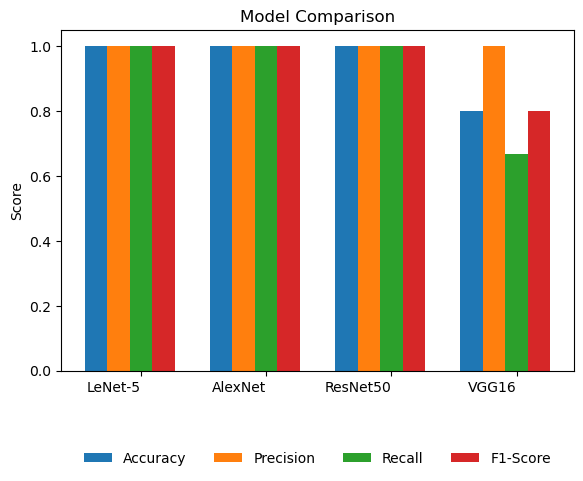

In [102]:
plot_full_metrics(final_table)